In [3]:
import numpy as np
from scipy import integrate
from scipy import optimize
from scipy.stats import norm, t 
import matplotlib.pyplot as plt
from scipy.special import logsumexp
import pandas as pd
from scipy.optimize._numdiff import approx_derivative

In [8]:
def log_likelihood(theta, y, v, scale):
    n = y.shape[0]
    log_like = - (v + 1) / 2 * np.sum(np.log1p(1 / (v * scale**2) * (theta - y)**2))
    return log_like

def log_prior(theta):
    return -np.log(1 + theta**2)

def log_joint(theta, y, v, scale):
    return log_likelihood(theta, y, v, scale) + log_prior(theta)

def neg_log_joint(theta, y, v, scale):
    return -log_joint(theta, y, v, scale)

def unnorm_posterior(theta, y, v, scale, m):
    return np.exp(log_joint(theta, y, v, scale) - m)

def kl_integrand(theta, y, v, scale, m, constant, log_g):
    log_p = log_posterior(theta, y, v, scale, m, constant)

    if not np.isfinite(log_p):
        return 0.0

    p = np.exp(log_p)

    if p == 0.0:
        return 0.0
    
    return (log_p - log_g(theta)) * p

def log_posterior(theta, y, v, scale, m, constant):
    return log_joint(theta, y, v, scale) - m - np.log(constant)


def log_skewed_laplace(theta, f, theta_map, y, v, scale):
    log_joint_theta = log_joint(theta, y, v, scale)
    log_joint_reflected = log_joint(2 * theta_map - theta, y, v, scale)

    log_weight = log_joint_theta - logsumexp([
        log_joint_theta,
        log_joint_reflected
    ])

    return np.log(2) + f.logpdf(theta) + log_weight


In [39]:
# consider varying n, v, and replicates

theta_true = 0.0
v_lik = 3
scale = 10.0


rng = np.random.default_rng(42)
n_replicates = 50
ns = [2, 4, 8, 16, 32, 64, 128, 256, 512]
vs = [2, 6, 18, 54, 162]

results = []

for r in range(n_replicates):
    
    for n in ns: 

        # gaussian
    
        samples = np.array(theta_true + scale * rng.standard_t(df=v_lik, size=n))

        # Candidate starting points: prior center and data quantiles
        starts = np.unique(
            np.r_[0.0, np.quantile(samples, [0, 0.25, 0.5, 0.75, 1])]
        )

        solutions = []

        for start in starts:

            result = optimize.minimize(
                neg_log_joint,
                x0=[start],
                args=(samples, v_lik, scale),
                method="BFGS"
            )

            if result.success and np.isfinite(result.fun):
                solutions.append(result)

        if not solutions:
            raise RuntimeError(
                f"MAP optimization failed: n={n}, replicate={r}"
            )

        # Select solution with highest log-posterior
        theta_map_opt = min(solutions, key=lambda result: result.fun)

        theta_map = float(theta_map_opt.x[0])
        
        m = log_joint(theta_map, samples, v_lik, scale)
        norm_constant, error = integrate.quad(unnorm_posterior, -np.inf, np.inf, args=(samples, v_lik, scale, m))
        J = (
            2 * (1 - theta_map**2) / (1 + theta_map**2)**2 - (v_lik + 1) * np.sum(((-v_lik * scale**2) + (theta_map - samples)**2) / (v_lik * scale**2 + (theta_map - samples)**2)**2) 
            )

        assert J > 0

        h_theta_map = 1 / J
        
        gaussian = norm(
            loc=theta_map,
            scale=np.sqrt(h_theta_map)
        )

        log_gaussian = gaussian.logpdf
        log_skew_gaussian = lambda theta: log_skewed_laplace(theta, gaussian, theta_map, samples, v_lik, scale)

        kl_gaussian = integrate.quad(kl_integrand, -np.inf, np.inf, args=(samples, v_lik, scale, m, norm_constant, log_gaussian))[0]
        kl_gaussian_skewed = integrate.quad(kl_integrand, -np.inf, np.inf, args=(samples, v_lik, scale, m, norm_constant, log_skew_gaussian))[0]

        tol = 1e-6
        
        if kl_gaussian_skewed > kl_gaussian + tol:
            print(f"Gaussian inequality violated: n={n}, replicate={r}")

        results.append({
            "n": n,
            "replicate": r,
            "family": "gaussian",
            "df": np.nan,
            "skewed": False,
            "kl": kl_gaussian
            })
        results.append({
            "n": n,
            "replicate": r,
            "family": "gaussian",
            "df": np.nan,
            "skewed": True,
            "kl": kl_gaussian_skewed
            })

        # t-students
        
        for v in vs:

            scale_sq = h_theta_map * (v + 1)/v

            student = t(
                df=v,
                loc=theta_map,
                scale=np.sqrt(scale_sq)
            )
            log_student = student.logpdf
            
            log_skew_student = lambda theta: log_skewed_laplace(theta, student, theta_map, samples, v_lik, scale)

            
                
            kl_t = integrate.quad(kl_integrand, -np.inf, np.inf, args=(samples, v_lik, scale, m, norm_constant, log_student))[0]
            kl_t_skewed = integrate.quad(kl_integrand, -np.inf, np.inf, args=(samples, v_lik, scale, m, norm_constant, log_skew_student))[0]

            

            if kl_t_skewed > kl_t + tol:
                print(f"Student-t inequality violated: " 
                      f"n={n}, replicate={r}, v={v}, "
                      f"plain={kl_t:.6g}, skewed={kl_t_skewed:.6g}"
                      )

            results.append({
                "n": n,
                "replicate": r,
                "family": "student_t",
                "df": v,
                "skewed": False,
                "kl": kl_t
                })
            results.append({
                "n": n,
                "replicate": r,
                "family": "student_t",
                "df": v,
                "skewed": True,
                "kl": kl_t_skewed
                })

df = pd.DataFrame(results)
    
df

,n,replicate,family,df,skewed,kl
0,2,0,gaussian,NaN,False,9.034200
1,2,0,gaussian,NaN,True,8.974144
2,2,0,student_t,2.0,False,0.145686
3,2,0,student_t,2.0,True,0.085630
4,2,0,student_t,6.0,False,0.766759
...,...,...,...,...,...,...
5395,512,49,student_t,18.0,True,0.000627
5396,512,49,student_t,54.0,False,0.001726
5397,512,49,student_t,54.0,True,0.001598
5398,512,49,student_t,162.0,False,0.003989


In [42]:
print("Non-finite KL:", (~np.isfinite(df["kl"])).sum())
print("Negative KL:", (df["kl"] < -1e-6).sum())

Non-finite KL: 0
Negative KL: 0


In [43]:
wide = df.pivot(
    index=["n", "replicate", "family", "df"],
    columns="skewed",
    values="kl"
).rename(columns={False: "plain", True: "skewed"})

# Include Gaussian despite its missing df
# (pivot_table would drop Gaussian by default)
wide = df.assign(
    df=df["df"].fillna(-1)
).pivot(
    index=["n", "replicate", "family", "df"],
    columns="skewed",
    values="kl"
).rename(columns={False: "plain", True: "skewed"})

wide["improvement"] = wide["plain"] - wide["skewed"]

print("Skew-correction violations:",
      (wide["improvement"] < -1e-6).sum())

print("Minimum improvement:", wide["improvement"].min())

Skew-correction violations: 0
Minimum improvement: 2.15341104503608e-06


In [15]:
df.to_csv("simulations_laplace_tstudent", index=False)

In [38]:
df.to_csv("simulations_laplace_tstudent_scale4", index=False)

In [44]:
df.to_csv("simulations_laplace_tstudent_scale10", index=False)

n=2: MAP=-0.1738, J=2.8415, normalization error=2.62e-08
n=8: MAP=-0.1907, J=7.0492, normalization error=2.60e-10
n=64: MAP=0.1454, J=46.2411, normalization error=7.18e-09


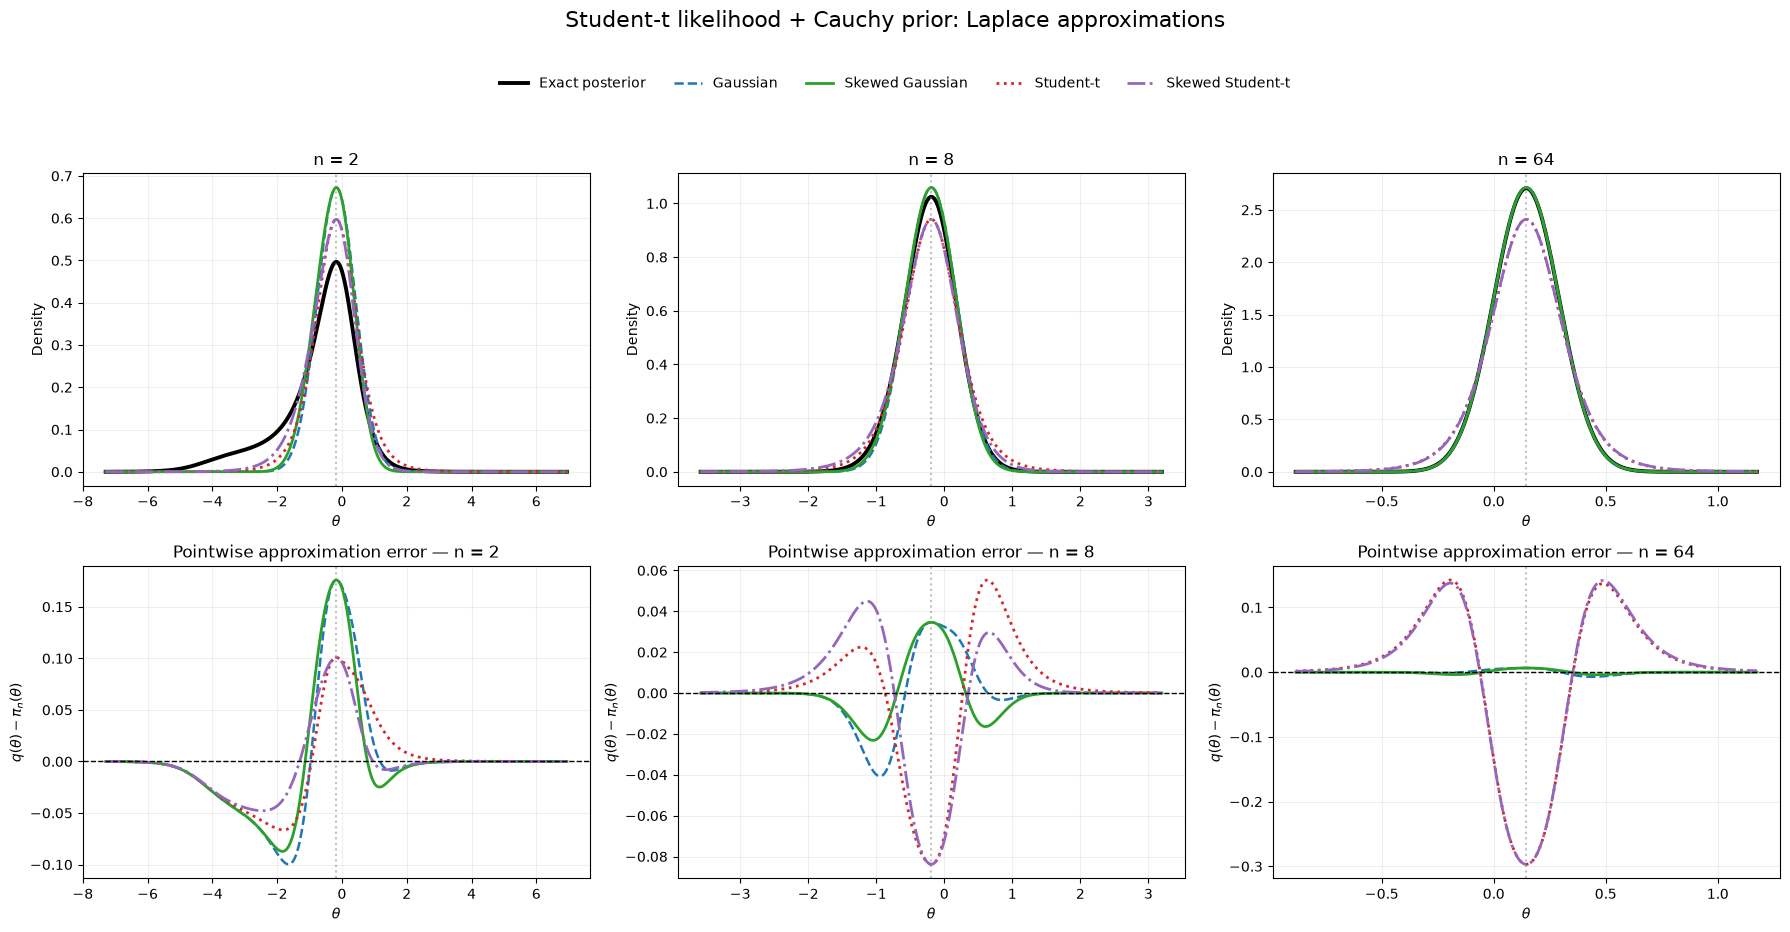

In [30]:

# ============================================================
# EXACT POSTERIOR VS FOUR LAPLACE APPROXIMATIONS
# STUDENT-T LIKELIHOOD + CAUCHY PRIOR
# ============================================================

theta_true = 0.0
v_lik = 3
scale = 1.0
v_approx = 6

rng_plot = np.random.default_rng(43) #43 for a weird one
selected_ns = [2, 8, 64]

fig, axes = plt.subplots(2, 3, figsize=(18, 9))

styles = {
    "Exact posterior": dict(color="black", lw=2.8, ls="-"),
    "Gaussian": dict(color="tab:blue", lw=1.8, ls="--"),
    "Skewed Gaussian": dict(color="tab:green", lw=2, ls="-"),
    "Student-t": dict(color="tab:red", lw=2, ls=":"),
    "Skewed Student-t": dict(color="tab:purple", lw=2, ls="-.")
}

datasets_plot = {}

for col, n in enumerate(selected_ns):

    # --------------------------------------------------------
    # GENERATE DATA
    # --------------------------------------------------------

    samples_plot = (
        theta_true
        + scale * rng_plot.standard_t(df=v_lik, size=n)
    )

    datasets_plot[n] = samples_plot.copy()

    # --------------------------------------------------------
    # MAP: MULTIPLE STARTING POINTS
    # --------------------------------------------------------

    starts = np.unique(
        np.r_[
            0.0,
            np.quantile(samples_plot, [0, 0.25, 0.5, 0.75, 1])
        ]
    )

    solutions = []

    for start in starts:
        result = optimize.minimize(
            neg_log_joint,
            x0=[start],
            args=(samples_plot, v_lik, scale),
            method="BFGS"
        )

        if result.success and np.isfinite(result.fun):
            solutions.append(result)

    if not solutions:
        raise RuntimeError(f"MAP optimization failed for n={n}")

    theta_map = float(
        min(solutions, key=lambda result: result.fun).x[0]
    )

    # --------------------------------------------------------
    # EXACT POSTERIOR NORMALIZATION
    # --------------------------------------------------------

    m = log_joint(theta_map, samples_plot, v_lik, scale)

    norm_constant, norm_error = integrate.quad(
        unnorm_posterior,
        -np.inf,
        np.inf,
        args=(samples_plot, v_lik, scale, m)
    )

    if not np.isfinite(norm_constant) or norm_constant <= 0:
        raise ValueError(f"Invalid normalization for n={n}")

    # --------------------------------------------------------
    # NEGATIVE HESSIAN AT MAP
    # --------------------------------------------------------

    residuals = theta_map - samples_plot

    J = (
        2 * (1 - theta_map**2) / (1 + theta_map**2)**2
        + (v_lik + 1) * np.sum(
            (v_lik * scale**2 - residuals**2)
            / (v_lik * scale**2 + residuals**2)**2
        )
    )

    if J <= 0:
        raise ValueError(f"Nonpositive curvature for n={n}: J={J}")

    # --------------------------------------------------------
    # LAPLACE APPROXIMATIONS
    # --------------------------------------------------------

    gaussian = norm(
        loc=theta_map,
        scale=np.sqrt(1 / J)
    )

    student = t(
        df=v_approx,
        loc=theta_map,
        scale=np.sqrt((v_approx + 1) / (v_approx * J))
    )

    # --------------------------------------------------------
    # EVALUATION GRID
    # --------------------------------------------------------

    sd = np.sqrt(1 / J)
    width = {2: 12, 8: 9, 64: 7}[n]

    theta_grid = np.linspace(
        theta_map - width * sd,
        theta_map + width * sd,
        2000
    )

    # --------------------------------------------------------
    # EXACT POSTERIOR
    # --------------------------------------------------------

    posterior = np.exp([
        log_posterior(
            theta,
            samples_plot,
            v_lik,
            scale,
            m,
            norm_constant
        )
        for theta in theta_grid
    ])

    # --------------------------------------------------------
    # SKEWED APPROXIMATIONS
    # --------------------------------------------------------

    skew_gaussian = np.exp([
        log_skewed_laplace(
            x, gaussian, theta_map,
            samples_plot, v_lik, scale
        )
        for x in theta_grid
    ])

    skew_student = np.exp([
        log_skewed_laplace(
            x, student, theta_map,
            samples_plot, v_lik, scale
        )
        for x in theta_grid
    ])

    densities = {
        "Exact posterior": posterior,
        "Gaussian": gaussian.pdf(theta_grid),
        "Skewed Gaussian": skew_gaussian,
        "Student-t": student.pdf(theta_grid),
        "Skewed Student-t": skew_student
    }

    # --------------------------------------------------------
    # TOP ROW: DENSITIES
    # --------------------------------------------------------

    ax = axes[0, col]

    for name, density in densities.items():
        ax.plot(
            theta_grid,
            density,
            label=name,
            **styles[name]
        )

    ax.axvline(theta_map, color="gray", ls=":", alpha=0.5)
    ax.set_title(f"n = {n}")
    ax.set_xlabel(r"$\theta$")
    ax.set_ylabel("Density")
    ax.grid(alpha=0.2)

    # --------------------------------------------------------
    # BOTTOM ROW: POINTWISE ERRORS
    # --------------------------------------------------------

    ax = axes[1, col]

    for name, density in densities.items():
        if name == "Exact posterior":
            continue

        ax.plot(
            theta_grid,
            density - posterior,
            label=name,
            **styles[name]
        )

    ax.axhline(0, color="black", ls="--", lw=1)
    ax.axvline(theta_map, color="gray", ls=":", alpha=0.5)

    ax.set_title(f"Pointwise approximation error — n = {n}")
    ax.set_xlabel(r"$\theta$")
    ax.set_ylabel(r"$q(\theta)-\pi_n(\theta)$")
    ax.grid(alpha=0.2)

    print(
        f"n={n}: MAP={theta_map:.4f}, "
        f"J={J:.4f}, "
        f"normalization error={norm_error:.2e}"
    )


# ============================================================
# SHARED LEGEND AND FORMATTING
# ============================================================

handles, labels = axes[0, 0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="upper center",
    ncol=5,
    bbox_to_anchor=(0.5, 0.97),
    frameon=False
)

fig.suptitle(
    "Student-t likelihood + Cauchy prior: Laplace approximations",
    fontsize=16,
    y=1.03
)

plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()
